# COMP0267 Coursework: compositional text–image models, from tensor networks to quantum circuits

In this coursework you build a model that decides whether a caption describes an image, in which **the meaning of a
sentence is computed from the meanings of its words, wired together by its grammar**. The same wiring can be
evaluated in two ways: as a classical **tensor network** or as a **parametrised quantum circuit**. You will train both,
then run the quantum model's circuits on simulated quantum hardware.

```
caption ──parse──▶ string diagram ──compile──▶ tensor network ──▶ text vector  ─┐
                                   └─compile──▶ quantum circuit ──▶ text state  ─┼─ InfoNCE vs. frozen CLIP image features
image ─────────────────────── CLIP ViT-B/32 ──▶ PCA ──▶ image vector / state ───┘
```

The data is **SVO-Probes** (Hendricks & Nematzadeh, 2021). Each row pairs a caption such as *"a father holds a baby"*
with an image it describes and a *negative* image that differs in the subject, the verb or the object. We evaluate two
two-way choices:

* **image choice**: given the caption, pick the positive image over the negative one;
* **caption choice** (the *swap test*): given the image, pick the caption over the same caption with subject and
  object swapped (*"a baby holds a father"*). Both captions contain exactly the same words.

### How to work and what to submit
* Open the notebook in Google Colab, choose a GPU runtime (*Runtime → Change runtime type → T4 GPU*; the emulators and
  the parser use it, and a CPU runtime also works), and run it from top to bottom. The first cell installs the course
  package; every provided cell runs as is. See the repository's README for a step-by-step setup guide.
* Questions are numbered **Q1–Q17**, with marks in brackets (**100 marks** in total). Answer in the cells marked
  **Answer** (markdown for derivations and discussion; code cells where asked). Keep answers concise: a derivation, a
  table or plot, and two or three sentences of interpretation is usually enough.
* The `modules/` package is a minimal skeleton. You may extend it, but say so in your answer, and keep the provided
  cells working.
* Section 6 (real quantum hardware) is optional and not marked.

| Part | Topic | Marks |
|---|---|---|
| 1 | Sentences as diagrams and tensor networks | 20 |
| 2 | Classical training with InfoNCE | 22 |
| 3 | A quantum model: parametrised circuits | 22 |
| 4 | Running the circuits: post-selection, shots and noise | 24 |
| 5 | Discussion | 12 |

## 0. Setup
The course code is the `comp0267` package. The cell below installs it with its requirements (about two minutes on
Colab; nothing to do if it is already installed). On a GPU runtime it also installs the GPU build of the Qiskit Aer
simulator, which the emulators in Part 4 use. Do not edit the package: build on it in this notebook, by importing its
classes and subclassing them, as Part 3 does with `Ansatz`.

In [1]:
import importlib.metadata
import importlib.util
import os
import subprocess
import sys

import torch

PACKAGE = os.environ.get("COMP0267_PACKAGE", "git+https://github.com/quantum-learning-labs/COMP0267_CW@main")


def pip(*args: str) -> None:
    subprocess.run([sys.executable, "-m", "pip", "-q", *args], check=True)


if importlib.util.find_spec("comp0267") is None:
    pip("install", PACKAGE)
if torch.cuda.is_available():  # swap Aer for its GPU build, same version
    try:
        importlib.metadata.version("qiskit-aer-gpu")
    except importlib.metadata.PackageNotFoundError:
        aer_version = importlib.metadata.version("qiskit-aer")
        pip("uninstall", "-y", "qiskit-aer")
        pip("install", f"qiskit-aer-gpu=={aer_version}")

In [2]:
from collections import Counter

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from torch import nn
from torch.utils.data import DataLoader

from comp0267.utils import get_device, set_seed

SEED = 0
BATCH_SIZE = 256
set_seed(SEED)
# Training contracts thousands of tiny tensors per batch, which is faster on the CPU than on a GPU (about 2x for the
# models below). Use `device = get_device()` to train on the GPU, e.g. for much larger wire dimensions or qubit counts.
device = torch.device("cpu")
print(f"training on {device}; GPU available: {torch.cuda.is_available()}")

training on cpu; GPU available: True


`load_svo_probes` downloads the processed data on first use (30 MB, cached): every row's caption, image ids and parsed
diagram, and the CLIP embedding of every image.

In [3]:
from comp0267.data import load_svo_probes

df, embeddings = load_svo_probes()
train, val, test = (df[df["legacy_split"] == split].reset_index(drop=True) for split in ("train", "val", "test"))
print(f"train {len(train)} | val {len(val)} | test {len(test)} rows, {len(embeddings)} image embeddings")
df[["corrected_sentence", "pos_triplet", "neg_triplet", "subj_neg", "verb_neg", "obj_neg"]].head()

downloading svo-probes:   0%|          | 0.00/15.5M [00:00<?, ?B/s]

train 5267 | val 1829 | test 1833 rows, 11750 image embeddings


,corrected_sentence,pos_triplet,neg_triplet,subj_neg,verb_neg,obj_neg
0,A father holds a baby.,"father,hold,baby","person,hold,baby",True,False,False
1,A woman walks through the meadow.,"woman,walk,meadow","horse,walk,meadow",True,False,False
2,The puppy sits on the grass.,"puppy,sit,grass","kitten,sit,grass",True,False,False
3,The boy swims on the water.,"boy,swim,water","['person,swim,water']",True,False,False
4,The man walks on the pier.,"man,walk,pier","man,walk,sidewalk",False,False,True


## Part 1. Sentences as diagrams and tensor networks (20 marks)

### 1.1 Grammar as wiring
A **combinatory categorial grammar (CCG)** parser assigns every word a type built from atomic types such as $n$ (noun)
and $s$ (sentence). A transitive verb, for example, has type $(s\backslash n)/n$: *give me a noun on the right and a
noun on the left and I return a sentence*. Translating each type into a list of **wires**, one per atomic type, gives
a transitive verb three wires $(n, s, n)$ and a noun one wire $(n)$. Grammatical reduction then **connects** the
subject's wire to the verb's left $n$ wire and the object's wire to its right $n$ wire. The verb's $s$ wire is left
open: it carries the meaning of the sentence.

The result is a **string diagram**. We store it as a list of boxes `(word, wires, types)`. Two boxes that share a wire
label are connected, and wire `0` is the sentence's output. Here is a caption from the training set, parsed by the
Bobcat parser and read off by `modules.diagrams.tree_to_diagram`:

In [4]:
from comp0267.diagrams import add_root, symbol

example = train.iloc[0]
print(example["corrected_sentence"])
for word, wires, types in example["corrected_sentence_diagram"]:
    print(f"  {word:>8}  wires {str(wires):12} types {types}")

A father holds a baby.
      baby  wires [3]          types ['n']
         a  wires [2, 3]       types ['n', 'n']
     holds  wires [1, 0, 2]    types ['n', 's', 'n']
    father  wires [4]          types ['n']
         a  wires [1, 4]       types ['n', 'n']


Every sentence is finally mapped to the same output space by a shared **`ROOT`** box. `add_root` finds the *head* box
that holds all open wires (here the verb), relabels those wires and plugs them into `ROOT`, whose last wire, of type
`out`, is the sentence's output. `ROOT` is one shared parameter tensor: it is the readout of the model.

In [5]:
for word, wires, types in add_root(example["corrected_sentence_diagram"]):
    print(f"  {word:>8}  wires {str(wires):12} types {types}")
print("\natomic types in the data:", Counter(t for d in df["corrected_sentence_diagram"] for _, _, ts in d for t in ts))

      baby  wires [3]          types ['n']
         a  wires [2, 3]       types ['n', 'n']
     holds  wires [1, 5, 2]    types ['n', 's', 'n']
    father  wires [4]          types ['n']
         a  wires [1, 4]       types ['n', 'n']
      ROOT  wires [5, 0]       types ['s', 'out']

atomic types in the data: Counter({'n': 88260, 's': 26129, 'p': 234})


The data's diagrams were produced by `parse`, and you can parse your own sentences. `load_parser` downloads the Bobcat
model on first use (about 0.8 GB, cached for the session; a GPU runtime parses faster but is not needed).

In [6]:
from comp0267.diagrams import load_parser, parse

parser = load_parser()
for word, wires, types in parse(["A dog chases a red ball."], parser)[0]:
    print(f"  {word:>8}  wires {str(wires):12} types {types}")

downloading bobcat:   0%|          | 0.00/827M [00:00<?, ?B/s]

      ball  wires [4]          types ['n']
       red  wires [3, 4]       types ['n', 'n']
         a  wires [2, 3]       types ['n', 'n']
    chases  wires [1, 0, 2]    types ['n', 's', 'n']
       dog  wires [5]          types ['n']
         a  wires [1, 5]       types ['n', 'n']


**Q1 (5 marks).** Take the caption above with its `ROOT` box. Suppose every wire of type $t$ is a vector-space index of
dimension $d_t$ (so a box with types $(n, s, n)$ is a tensor in $\mathbb{R}^{d_n \times d_s \times d_n}$).
(a) Give the shape of every tensor. (b) Write the sentence vector as an explicit sum over indices, e.g.
$v_o = \sum_{i,j,\dots} \text{baby}_i \, a_{ji} \cdots$, and say which sums are the connections of the diagram.
(c) What role does a determiner box like `a`, of type $(n, n)$, play, and how does the model share parameters
across sentences?

**Answer Q1.** *Write your answer here.*

**Q2 (5 marks).** View a diagram as a graph whose vertices are boxes and whose edges are connected wires.
(a) Argue that every diagram produced by function application and composition in a CCG derivation is a **tree** once
parallel wires (several wires joining the same two boxes) are merged into one edge.
(b) Hence show that, for fixed wire dimensions, the sentence vector can be computed in time *linear* in the number of
words (contract leaves into their parents). (c) Give an example of a linguistic phenomenon that would add a cycle to
the graph, and say what happens to the cost of exact contraction for graphs of large treewidth.

**Answer Q2.** *Write your answer here.*

### 1.2 Compiling diagrams into tensor networks
`TNCompiler` turns a diagram into a **recipe**: an `einsum` string plus one `Op` per tensor. The `Op`'s name is the
word's *symbol* (`word_types`), so every occurrence of the same word with the same types reuses the same tensor. Boxes
with more than two wires (verbs, `ROOT`) can be stored as a **matrix product state** (MPS): a chain of small cores
joined by *bond* wires of dimension $\chi$ (`bond_dim`). This caps the number of parameters.

In [7]:
from comp0267.classical import PCA, TNCompiler, TNModel

DIMS = {"n": 8, "s": 8, "p": 8, "out": 64}  # wire dimension per type; `out` must match the image features below
tn_compiler = TNCompiler(DIMS, bond_dim=4)

recipe = tn_compiler(example["corrected_sentence_diagram"])
print(recipe.einsum)
for op in recipe.ops:
    print("  ", op)

for split in (train, val, test):
    split["tn"] = split["corrected_sentence_diagram"].map(tn_compiler)

d,cd,bg,gfh,hc,e,be,fa->a
   Op(name='baby_n', kind='tensor', shape=(8,))
   Op(name='a_n@n', kind='tensor', shape=(8, 8))
   Op(name='holds_n@s@n_core0', kind='tensor', shape=(8, 4))
   Op(name='holds_n@s@n_core1', kind='tensor', shape=(4, 8, 4))
   Op(name='holds_n@s@n_core2', kind='tensor', shape=(4, 8))
   Op(name='father_n', kind='tensor', shape=(8,))
   Op(name='a_n@n', kind='tensor', shape=(8, 8))
   Op(name='ROOT_s@out', kind='tensor', shape=(8, 64))


**Q3 (6 marks).** (a) For a transitive verb with types $(n, s, n)$, give the number of parameters as a full tensor and
as an MPS with bond dimension $\chi$; for which $\chi$ does the MPS save parameters? (b) The MPS constrains the verb:
show that, viewed as a matrix from the subject wire to the $(s, n_{\text{object}})$ wires, it has rank at most $\chi$.
(c) In code, build the model without MPS (`bond_dim=None`) and compare its total parameter count with the MPS model
below. Which part of the model dominates the count?

**Answer Q3.** *Write your answer here.*

In [8]:
# Q3 (c): your code here

A model only has tensors for the symbols it saw in training. Captions with an unseen symbol cannot be evaluated; we
drop them and report how many remain.

In [9]:
tn_model = TNModel(train["tn"]).to(device)
print(f"{len(tn_model.symbols())} symbols, {sum(p.numel() for p in tn_model.parameters())} parameters")
for name, split in (("val", val), ("test", test)):
    print(f"{name}: {split['tn'].map(tn_model.knows).mean():.1%} of captions use only known symbols")

251 symbols, 13976 parameters
val: 99.2% of captions use only known symbols
test: 99.2% of captions use only known symbols


**Q4 (4 marks).** Find the most frequent unseen symbols in the test set and explain why they are unseen (look at their
types as well as their words). Propose two ways a compositional model could handle unseen words, with one advantage
and one drawback each.

**Answer Q4.** *Write your answer here.*

In [10]:
# Q4: your code here

## Part 2. Classical training with InfoNCE (22 marks)

### 2.1 The image side
Images are encoded once by the CLIP ViT-B/32 image encoder (512 numbers per image), which stays **frozen**: only the
text model learns, so it must learn to land in the space CLIP has already organised (this is *locked-image tuning*).
To match the text output dimension we project onto the top `DIMS["out"]` principal components of the training images.

In [11]:
from comp0267.data import ChoiceDataset, build_swap_set, collate


def image_matrix(ids) -> torch.Tensor:
    return torch.stack([embeddings[int(i)] for i in ids])


train_images = image_matrix(train["pos_image_id"].unique())
tn_image_model = PCA(DIMS["out"]).fit(train_images).to(device)


def image_choice(split: pd.DataFrame, col: str, model) -> ChoiceDataset:
    # caption, its image and the negative image, for the rows whose symbols the model knows
    rows = split[split[col].map(model.knows)]
    return ChoiceDataset(rows[col], rows["pos_image_id"], embeddings, rows["neg_image_id"], "image")


def caption_choice(swap: pd.DataFrame, col: str, model) -> ChoiceDataset:
    # caption, its image and the caption with subject and object swapped
    rows = swap[swap[col].map(model.knows) & swap[f"{col}_swapped"].map(model.knows)]
    return ChoiceDataset(rows[col], rows["pos_image_id"], embeddings, rows[f"{col}_swapped"], "caption")


swap_val, swap_test = build_swap_set(val), build_swap_set(test)
for swap in (swap_val, swap_test):
    swap["tn"] = swap["corrected_sentence_diagram"].map(tn_compiler)
    swap["tn_swapped"] = swap["swapped_sentence_diagram"].map(tn_compiler)
print(f"swap sets: {len(swap_val)} val and {len(swap_test)} test rows")
swap_test[["corrected_sentence", "swapped_sentence"]].head(3)

swap sets: 1761 val and 1777 test rows


,corrected_sentence,swapped_sentence
0,The person rests on the beach.,the beach rests on the person.
1,A child walks in a field.,a field walks in a child.
2,A man sits by a lake.,a lake sits by a man.


### 2.2 The InfoNCE loss
Take a batch of $B$ matched pairs $(t_i, v_i)$ of text and image vectors and let $s_{ij} = \cos(t_i, v_j)$. InfoNCE
treats each row of the similarity matrix as a $B$-way classification, *which image belongs to caption $i$?*, with
logits $s_{ij}/\tau$, and does the same for each column:
$$
\mathcal{L} = -\frac{1}{2B}\sum_{i=1}^{B}\left[\log\frac{e^{s_{ii}/\tau}}{\sum_{j} e^{s_{ij}/\tau}}
            + \log\frac{e^{s_{ii}/\tau}}{\sum_{j} e^{s_{ji}/\tau}}\right].
$$
The other $B-1$ items of the batch act as negatives. The temperature $\tau$ sets how sharply the loss focuses on the
hardest negatives.

**Q5 (6 marks).** (a) Show that if all similarities are equal, $\mathcal{L} = \log B$, and evaluate it for our batch
size. The quantum model in Part 3 ends training with a loss *above* this value, yet beats chance on validation. Explain
how (hint: what is the expected loss of a model whose similarities are random rather than equal?). (b) For the text-to-image term of row $i$, show that
$\partial \mathcal{L}_i / \partial s_{ij} = (p_{ij} - \delta_{ij})/\tau$ with $p_{ij}$ the softmax probabilities, and
interpret this as attraction and repulsion. (c) What happens to $p_{ij}$ as $\tau \to 0$ and as $\tau \to \infty$?
Since $s_{ij} \in [-1, 1]$, what is the smallest loss reachable for a given $\tau$?

**Answer Q5.** *Write your answer here.*

### 2.3 Training
`fit` is a plain training loop, shared by the classical and the quantum model. After every epoch it evaluates the
two-way choices on the validation set with `choice_scores` (1 if the positive scores higher, ½ on a tie, 0 otherwise).

In [12]:
from comp0267.training import InfoNCE, choice_scores, cosine, fidelity


def accuracy(text_model, image_model, dataset, similarity) -> float:
    loader = DataLoader(dataset, batch_size=BATCH_SIZE, collate_fn=collate)
    return choice_scores(text_model, image_model, loader, similarity).mean().item()


def fit(text_model, image_model, loss_fn, train_set, epochs, lr, val_sets, similarity) -> pd.DataFrame:
    optimizer = torch.optim.Adam(text_model.parameters(), lr=lr)
    loader = DataLoader(train_set, batch_size=BATCH_SIZE, shuffle=True, collate_fn=collate)
    history = []
    for epoch in range(1, epochs + 1):
        text_model.train()
        total = 0.0
        for batch in loader:
            loss = loss_fn(text_model(batch["caption"]), image_model(batch["image"].to(device)))
            optimizer.zero_grad()
            loss.backward()
            optimizer.step()
            total += loss.item() * len(batch["caption"])
        history.append({"epoch": epoch, "loss": total / len(train_set),
                        **{name: accuracy(text_model, image_model, ds, similarity) for name, ds in val_sets.items()}})
        print(" | ".join(f"{k} {v:.4f}" if isinstance(v, float) else f"{k} {v}" for k, v in history[-1].items()))
    return pd.DataFrame(history)


def plot_history(history: pd.DataFrame, title: str) -> None:
    fig, (ax_loss, ax_acc) = plt.subplots(1, 2, figsize=(10, 3.5))
    ax_loss.plot(history["epoch"], history["loss"])
    ax_loss.set(xlabel="epoch", ylabel="training loss", title=title)
    for col in history.columns.drop(["epoch", "loss"]):
        ax_acc.plot(history["epoch"], history[col], label=col)
    ax_acc.axhline(0.5, color="grey", ls=":", label="chance")
    ax_acc.set(xlabel="epoch", ylabel="validation accuracy")
    ax_acc.legend()
    plt.show()

epoch 1 | loss 5.7763 | image choice 0.5788 | swap 0.5667


epoch 2 | loss 5.1208 | image choice 0.6053 | swap 0.5902


epoch 3 | loss 4.7895 | image choice 0.6461 | swap 0.6222


epoch 4 | loss 4.5727 | image choice 0.6560 | swap 0.6451


epoch 5 | loss 4.3858 | image choice 0.6389 | swap 0.6617


epoch 6 | loss 4.2124 | image choice 0.6521 | swap 0.6709


... (20 outputs left out)

epoch 27 | loss 2.7104 | image choice 0.7773 | swap 0.8483


epoch 28 | loss 2.7033 | image choice 0.7751 | swap 0.8592


epoch 29 | loss 2.6836 | image choice 0.7685 | swap 0.8603


epoch 30 | loss 2.6730 | image choice 0.7795 | swap 0.8449


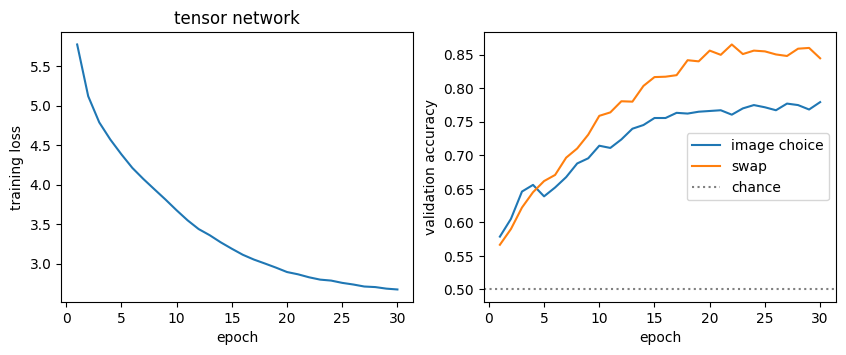

In [13]:
TN_EPOCHS, TN_LR = 30, 3e-2

set_seed(SEED)
tn_model = TNModel(train["tn"]).to(device)
tn_history = fit(tn_model, tn_image_model, InfoNCE(cosine), image_choice(train, "tn", tn_model), TN_EPOCHS, TN_LR,
                 {"image choice": image_choice(val, "tn", tn_model), "swap": caption_choice(swap_val, "tn", tn_model)},
                 cosine)
plot_history(tn_history, "tensor network")

### 2.4 Test accuracy

In [14]:
tn_test_image = image_choice(test, "tn", tn_model)
tn_test_swap = caption_choice(swap_test, "tn", tn_model)
results = {"tensor network": {
    "image choice": accuracy(tn_model, tn_image_model, tn_test_image, cosine),
    "swap": accuracy(tn_model, tn_image_model, tn_test_swap, cosine),
    "parameters": sum(p.numel() for p in tn_model.parameters())}}
pd.DataFrame(results).T

,image choice,swap,parameters
tensor network,0.773377,0.872944,13976.0


**Q6 (8 marks).** (a) Prove that any model whose caption vector depends only on the *multiset* of its words (a
*bag-of-words* model) scores exactly 0.5 on the swap test. (b) Implement a bag-of-words baseline: one trainable vector
of size `DIMS["out"]` per word, summed over the caption's words (you can read the words off the `Op` names of a
recipe, or off the diagram). Train it with `fit` and add its test accuracies to `results`.
(c) Compare it with the tensor network on both tasks. What does the comparison say about what each task measures?

In [15]:
# Q6 (b): your code here

**Answer Q6.** *Write your answer here.*

**Q7 (4 marks).** Break the tensor network's test image-choice accuracy down by what the negative image changes
(`subj_neg`, `verb_neg`, `obj_neg`; `choice_scores` returns one score per row, in dataset order). Which kind of
negative is hardest, and why might that be? Consider both the text model and the frozen image features.

In [16]:
# Q7: your code here

**Answer Q7.** *Write your answer here.*

**Q8 (4 marks).** InfoNCE assumes that the only correct image for caption $i$ in a batch is image $i$. In SVO-Probes,
the same image (and the same caption) often appears in several rows. Measure how many *false negatives* (off-diagonal
pairs with the same positive image) a random batch of 256 training rows contains on average. Explain how they bias
the loss, and propose a fix.

In [17]:
# Q8: your code here

**Answer Q8.** *Write your answer here.*

## Part 3. A quantum model: parametrised circuits (22 marks)

### 3.1 From diagrams to circuits
The same diagrams can be evaluated on a quantum computer:
* every wire of type $t$ becomes $q_t$ **qubits** (a $2^{q_t}$-dimensional space);
* every word becomes a **parametrised circuit** (an *ansatz*) acting on $|0\dots0\rangle$ for all of its qubits, so a
  word is a state $|w(\theta_w)\rangle$ prepared by a unitary;
* every connection between two boxes becomes a **cup**: the effect $\langle 00| + \langle 11|$ on the two qubits it
  joins. In the einsum this is just a shared index. On a device, it is a Bell-basis measurement whose outcome we
  **post-select**.

The text state is therefore $|t\rangle = \big(\bigotimes_{\text{cups}} (\langle 00|+\langle 11|)\big)
\bigotimes_{\text{words}} |w\rangle$. This vector is *unnormalised*, and its norm will matter in Part 4.
Unlike the tensor network, we read the sentence directly off the head word's open $s$ qubits, with no `ROOT` box
(Q12 shows why), so the image state must live on the same number of qubits. `modules.quantum.Ansatz` does the wiring;
a subclass only says which gates a word applies to its qubits. Our first ansatz is a layer of $R_y$ and $R_z$
rotations followed by a ladder of CNOTs, repeated `layers` times:

In [18]:
from comp0267.quantum import AngleEncoder, Ansatz, VQCModel


class RyRzCXAnsatz(Ansatz):
    # per layer: Ry then Rz on every qubit of the word, then CX between neighbours
    def word_circuit(self, circuit, wires, name):
        for layer in range(self.layers):
            for q in range(len(wires)):
                circuit.apply("Ry", wires, [q], f"{name}_l{layer}_y{q}")
                circuit.apply("Rz", wires, [q], f"{name}_l{layer}_z{q}")
            for q in range(len(wires) - 1):
                circuit.apply("CX", wires, [q, q + 1])


QUBITS = {"n": 1, "s": 1, "p": 1}  # qubits per wire type; the sentence state lives on the s qubits
VQC_LAYERS, VQC_EPOCHS, VQC_LR = 2, 20, 5e-2
vqc_ansatz = RyRzCXAnsatz(QUBITS, layers=VQC_LAYERS)
for split in (train, val, test):
    split["vqc"] = split["corrected_sentence_diagram"].map(vqc_ansatz)
for swap in (swap_val, swap_test):
    swap["vqc"] = swap["corrected_sentence_diagram"].map(vqc_ansatz)
    swap["vqc_swapped"] = swap["swapped_sentence_diagram"].map(vqc_ansatz)

set_seed(SEED)
vqc_model = VQCModel(train["vqc"]).to(device)
print(f"{len(vqc_model.symbols())} angles")

1176 angles


The circuit of the example caption, with its current (random) angles:

In [19]:
from comp0267.circuits import to_circuit

example_circuit = to_circuit(test["vqc"].iloc[0], vqc_model.angle_dict())
print(test["corrected_sentence"].iloc[0], "|", example_circuit.metadata)
example_circuit.draw(fold=-1)

The person rests on the beach. | {'postselect': [0, 2, 1, 7, 3, 9, 4, 8, 5, 11, 10, 12], 'outputs': [6]}


┌─────────────┐ ┌─────────────┐ ┌─────────────┐┌─────────────┐                                                   ┌───┐                                        
 q_0: ┤ Ry(-1.5615) ├─┤ Rz(-2.4074) ├─┤ Ry(-2.9401) ├┤ Rz(-2.6515) ├───────────────────────────────────────■───────────┤ H ├────────────────────────────────────────
      ├─────────────┴┐├─────────────┴┐└─────────────┘├─────────────┴┐┌─────────────┐                       │           └───┘                                   ┌───┐
 q_1: ┤ Ry(-0.26709) ├┤ Rz(-0.01932) ├───────■───────┤ Ry(-0.67585) ├┤ Rz(-2.1845) ├────────■──────────────┼────────────────────────────────────────────────■──┤ H ├
      ├─────────────┬┘├─────────────┬┘     ┌─┴─┐     └┬────────────┬┘├─────────────┤      ┌─┴─┐          ┌─┴─┐                                              │  └───┘
 q_2: ┤ Ry(-2.4501) ├─┤ Rz(-2.6077) ├──────┤ X ├──────┤ Ry(1.8207) ├─┤ Rz(-2.1176) ├──────┤ X ├──────────┤ X ├──────────────────────────────────────────────┼───────
      └┬────────────┤ ├─────────────┤      └───┘     ┌┴────────────┤ ├─────────────┴┐     └───┘          └───┘                        ┌───┐                 │       
 q_3: ─┤ Ry(1.9013) ├─┤ Rz(0.28606) ├────────■───────┤ Ry(0.91989) ├─┤ Rz(-0.88902) ├──────────────────────■───────────────────────■──┤ H ├─────────────────┼───────
      ┌┴────────────┤ ├─────────────┤      ┌─┴─┐     └─────────────┘ ├─────────────┬┘ ┌────────────┐     ┌─┴─┐                     │  └───┘     ┌───┐       │       
 q_4: ┤ Ry(-1.6288) ├─┤ Rz(-2.1961) ├──────┤ X ├────────────■────────┤ Ry(-2.2337) ├──┤ Rz(1.4786) ├─────┤ X ├───────────■─────────┼─────────■──┤ H ├───────┼───────
      ├─────────────┤ └┬────────────┤      └───┘          ┌─┴─┐      └─────────────┘ ┌┴────────────┤ ┌───┴───┴────┐    ┌─┴─┐       │         │  └───┘       │  ┌───┐
 q_5: ┤ Ry(-0.6119) ├──┤ Rz(2.6743) ├─────────────────────┤ X ├─────────────■────────┤ Ry(-2.4929) ├─┤ Rz(2.6996) ├────┤ X ├───────┼────■────┼─────────■────┼──┤ H ├
      └┬────────────┤ ┌┴────────────┴┐                    └───┘           ┌─┴─┐      └─────────────┘┌┴────────────┤┌───┴───┴────┐  │  ┌─┴─┐  │         │    │  └───┘
 q_6: ─┤ Ry(2.4937) ├─┤ Rz(-0.40611) ├────────────────────────────────────┤ X ├─────────────■───────┤ Ry(0.19138) ├┤ Rz(2.0837) ├──┼──┤ X ├──┼────■────┼────┼───────
      ┌┴────────────┴┐├─────────────┬┘                                    └───┘           ┌─┴─┐     └┬────────────┤├────────────┤  │  └───┘  │  ┌─┴─┐  │  ┌─┴─┐     
 q_7: ┤ Ry(-0.71053) ├┤ Rz(-2.2977) ├─────────────────────────────────────────────────────┤ X ├──────┤ Ry(2.4908) ├┤ Rz(-1.648) ├──┼─────────┼──┤ X ├──┼──┤ X ├─────
      ├──────────────┤├─────────────┤                 ┌────────────┐  ┌────────────┐      └───┘      └────────────┘└────────────┘  │       ┌─┴─┐└───┘  │  └───┘     
 q_8: ┤ Ry(-0.56805) ├┤ Rz(0.17795) ├────────■────────┤ Ry(1.3688) ├──┤ Rz(1.3593) ├────────■──────────────────────────────────────┼───────┤ X ├───────┼────────────
      └┬───────────┬─┘└┬────────────┤      ┌─┴─┐     ┌┴────────────┴┐ ├────────────┤      ┌─┴─┐                                  ┌─┴─┐     └───┘       │            
 q_9: ─┤ Ry(2.053) ├───┤ Rz(1.1867) ├──────┤ X ├─────┤ Ry(-0.77084) ├─┤ Rz(2.3183) ├──────┤ X ├──────────────────────────────────┤ X ├─────────────────┼────────────
      ┌┴───────────┴┐  ├───────────┬┘ ┌────┴───┴────┐└┬────────────┬┘ └────────────┘      └───┘                        ┌───┐     └───┘                 │            
q_10: ┤ Ry(0.48378) ├──┤ Rz(1.883) ├──┤ Ry(-2.8324) ├─┤ Rz(2.8399) ├───────────────────────────────────────■───────────┤ H ├───────────────────────────┼────────────
      ├─────────────┴┐┌┴───────────┴─┐└─────────────┘┌┴────────────┴┐┌─────────────┐                       │           └───┘                         ┌─┴─┐          
q_11: ┤ Ry(-0.26709) ├┤ Rz(-0.01932) ├───────■───────┤ Ry(-0.67585) ├┤ Rz(-2.1845) ├────────■──────────────┼─────────────────────────────────────────┤ X ├──────────
      ├─────────────┬┘├─────────────┬┘     ┌─┴

**Q9 (5 marks).** (a) Show that for single-qubit states $|\psi\rangle, |\phi\rangle$,
$(\langle 00| + \langle 11|)(|\psi\rangle \otimes |\phi\rangle) = \sum_x \psi_x \phi_x$, and use it to explain why a cup
"bends" a wire: an output of one box becomes an input of another (the snake equation). (b) The circuit above
implements each cup with a CNOT, a Hadamard and the post-selection of both qubits on 0. Show that this projects
onto $(|00\rangle + |11\rangle)/\sqrt{2}$, and hence that the circuit's amplitudes are those of $|t\rangle$ times
$2^{-c/2}$ for $c$ cups.

**Answer Q9.** *Write your answer here.*

### 3.2 The image side: an angle encoding
The image becomes a quantum state too, on as many qubits as the sentence wire. We take $2 \times$ (qubits) $\times$
(layers) whitened principal components $x$ of its CLIP embedding and use them as rotation angles, uploading new
features in every layer:
$|v(x)\rangle = \prod_{\ell}\big[\mathrm{CX\ ladder}\big]\big[\bigotimes_k R_z(x'_{\ell k}) R_y(x_{\ell k})\big]|0\dots0\rangle$.

In [20]:
encoder = AngleEncoder(n_qubits=QUBITS["s"], layers=4)
vqc_image_model = nn.Sequential(PCA(encoder.n_features, whiten=True).fit(train_images), encoder).to(device)
print(f"{encoder.n_features} image features -> {2 ** encoder.n_qubits}-dimensional state")

8 image features -> 2-dimensional state


**Q10 (4 marks).** (a) Show that $R_y(a) R_y(b) = R_y(a+b)$, and explain why stacking layers of $R_y$ alone on one
qubit gives no more expressive power than a single $R_y$. (b) Which single-qubit states can $R_z(\beta) R_y(\alpha)|0\rangle$
reach? Give their Bloch-sphere coordinates. (c) Our encoder puts 8 features on one qubit by re-uploading them over
4 layers. How many real parameters does a one-qubit pure state have, and what does that imply for the map from 8
features to the state? Why do we whiten the features before using them as angles?

**Answer Q10.** *Write your answer here.*

### 3.3 Training with a fidelity-based InfoNCE
For quantum states the natural similarity is the **fidelity** $s_{ij} = |\langle \hat t_i | v_j \rangle|^2 \in [0, 1]$,
with $\hat t = t / \lVert t \rVert$ the normalised (post-selected) text state. It is exactly what we will measure on a
device in Part 4. `VQCModel` contracts the circuits' tensors exactly, a *perfect simulation*, so gradients are exact.

epoch 1 | loss 9.1874 | image choice 0.5518 | swap 0.5238


epoch 2 | loss 8.1832 | image choice 0.5535 | swap 0.5060


epoch 3 | loss 7.8536 | image choice 0.5535 | swap 0.5215


epoch 4 | loss 7.6116 | image choice 0.5391 | swap 0.5209


epoch 5 | loss 7.4886 | image choice 0.5513 | swap 0.5226


epoch 6 | loss 7.4149 | image choice 0.5524 | swap 0.5312


... (10 outputs left out)

epoch 17 | loss 6.9646 | image choice 0.5430 | swap 0.5455


epoch 18 | loss 6.9315 | image choice 0.5568 | swap 0.5329


epoch 19 | loss 6.8719 | image choice 0.5612 | swap 0.5518


epoch 20 | loss 6.9235 | image choice 0.5557 | swap 0.5730


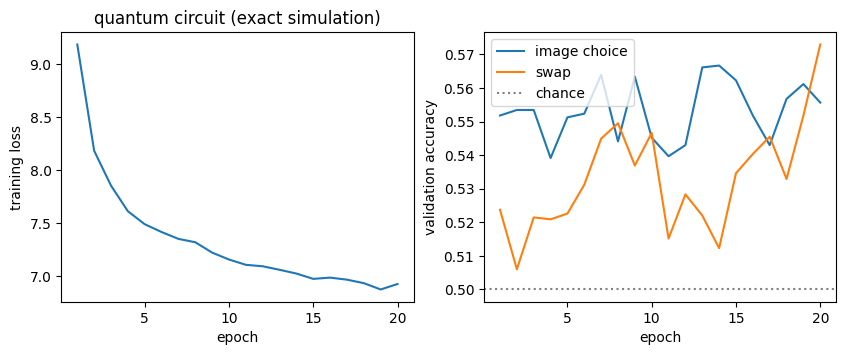

In [21]:
vqc_history = fit(vqc_model, vqc_image_model, InfoNCE(fidelity), image_choice(train, "vqc", vqc_model), VQC_EPOCHS,
                  VQC_LR, {"image choice": image_choice(val, "vqc", vqc_model),
                           "swap": caption_choice(swap_val, "vqc", vqc_model)}, fidelity)
plot_history(vqc_history, "quantum circuit (exact simulation)")

In [22]:
vqc_test_image = image_choice(test, "vqc", vqc_model)
results["quantum circuit (exact)"] = {
    "image choice": accuracy(vqc_model, vqc_image_model, vqc_test_image, fidelity),
    "swap": accuracy(vqc_model, vqc_image_model, caption_choice(swap_test, "vqc", vqc_model), fidelity),
    "parameters": vqc_model.angles.numel()}
pd.DataFrame(results).T

,image choice,swap,parameters
tensor network,0.773377,0.872944,13976.0
quantum circuit (exact),0.556656,0.595008,1176.0


**Q11 (8 marks).** Design and train a better quantum text model. Change the ansatz (e.g. add $R_z$ rotations,
controlled rotations `CRz`, more layers), the qubits per type in `QUBITS`, and/or the image encoder's layers (its
qubits must match `QUBITS["s"]`). Report validation and test accuracies, the number of
parameters and the mean number of qubits per caption for each design in a table, and explain your choices. Keep the
qubit count in mind: Part 4 shows what it costs.

In [23]:
# Q11: your code here

**Answer Q11.** *Write your answer here.*

**Q12 (5 marks).** Why is there no `ROOT` box in the quantum model? (a) Compile the captions with
`RyRzCXAnsatz({**QUBITS, "out": 1}, layers=VQC_LAYERS, root=True)`, train that model as above, and measure the mean
fidelity between the text states of *different* captions (the off-diagonal mean of `fidelity(t, t)` over a few hundred
captions) before and after training. Do the same for the model trained above. (b) View the `ROOT` cup as a linear map
$M$ from the $s$ qubit to the output qubit. Explain how $M$ can make all captions look alike, and why InfoNCE can push a
weak text model towards this collapse. (c) `VQCModel` draws its initial angles from $[-\pi, \pi]$ (`init_scale`).
What do all text states look like for `init_scale=0.1`, and what does that mean for the first steps of training?

In [24]:
# Q12: your code here

**Answer Q12.** *Write your answer here.*

## Part 4. Running the circuits: post-selection, shots and noise (24 marks)

So far we have computed $|t\rangle$ exactly. A quantum computer instead *samples*: we prepare the state, measure, and
repeat for many **shots**. Two things change. First, the cups only work when their post-selection succeeds, so most
shots are thrown away. Second, we only get estimates of the fidelities, and on real devices noisy ones.

### 4.1 The post-selection budget

In [25]:
@torch.no_grad()
def acceptance(model, recipes) -> torch.Tensor:
    # probability that every cup's Bell measurement succeeds: ||t||^2 / 2^(number of cups)
    norms = torch.cat([model(recipes[i:i + BATCH_SIZE]).abs().square().sum(1).cpu()
                       for i in range(0, len(recipes), BATCH_SIZE)])
    cups = torch.tensor([(sum(op.kind == "0" for op in r.ops) - QUBITS["s"]) / 2 for r in recipes])
    return norms / 2 ** cups


known = test[test["vqc"].map(vqc_model.knows)].reset_index(drop=True)
known["qubits"] = known["vqc"].map(lambda r: sum(op.kind == "0" for op in r.ops))
known["p_accept"] = acceptance(vqc_model, list(known["vqc"])).numpy()
known.groupby("qubits")["p_accept"].describe()[["count", "mean", "50%", "min"]]

,count,mean,50%,min
qubits,,,,
7,9.0,2.438941e-02,2.953221e-02,4.412677e-03
9,97.0,4.358991e-03,3.721470e-03,1.502743e-04
11,94.0,9.150938e-04,6.849343e-04,8.788282e-05
13,1544.0,3.054542e-04,2.487621e-04,1.815476e-06
15,16.0,9.136995e-05,6.393987e-05,3.155395e-05
17,28.0,1.179256e-05,5.410307e-06,1.758790e-06
19,15.0,2.864025e-06,2.082752e-06,3.626388e-07
21,14.0,1.061007e-06,6.918852e-07,4.120506e-08
25,1.0,2.874295e-08,2.874295e-08,2.874295e-08


**Q13 (6 marks).** (a) Using Q9, show that the probability that all $c$ post-selections succeed is
$p_{\text{accept}} = \lVert t\rVert^2 / 2^{c}$. (b) Plot $p_{\text{accept}}$ against the number of qubits (log scale)
and fit the trend. (c) How many shots does the median test caption of each size need for 1000 accepted shots in
expectation? What does this imply for the qubit counts you chose in Q11?

In [26]:
# Q13: your code here

**Answer Q13.** *Write your answer here.*

### 4.2 Measuring the overlap: compute–uncompute
To estimate $|\langle v | \hat t \rangle|^2$, we run the text circuit, then the **inverse** image circuit $V^\dagger$ on
the text's output qubits, and measure all qubits. Among the shots whose cups succeeded, the fraction in which the
output qubits all read 0 estimates the fidelity. `overlap_circuit` builds this circuit and `exact_overlap` computes
its outcome probabilities from the statevector. We check below that they agree with the torch model.

Q13 shows why we cannot afford every caption. We emulate `N_EMULATE` test rows with at most `MAX_QUBITS` qubits,
mostly captions without determiners such as *"man rides horse"*. This subset is not representative, so compare
emulated accuracies with the exact accuracy *on the same rows*, not with the test accuracy above. Each row needs two
circuits: caption against positive image, and caption against negative image.

In [27]:
from comp0267.circuits import estimate_overlap, exact_overlap, overlap_circuit, sample

N_EMULATE, MAX_QUBITS, SHOTS = 50, 9, 2 ** 16
pca, encoder = vqc_image_model
angles = vqc_model.angle_dict()


def image_circuit(image_id: int):
    features = pca(embeddings[int(image_id)][None])[0].cpu()
    return to_circuit(encoder.recipe, encoder.angle_dict(features))


rows = known[known["qubits"] <= MAX_QUBITS].head(N_EMULATE).reset_index(drop=True)
circuits = []  # per row: [caption vs positive image, caption vs negative image], unmeasured
for _, row in rows.iterrows():
    text_circuit = to_circuit(row["vqc"], angles)
    circuits.append([overlap_circuit(text_circuit, image_circuit(row[col]), measure=False)
                     for col in ("pos_image_id", "neg_image_id")])

exact = np.array([[exact_overlap(qc)[1] for qc in pair] for pair in circuits])
with torch.no_grad():
    text = vqc_model(list(rows["vqc"]))
    torch_fidelity = np.stack([fidelity(text, vqc_image_model(image_matrix(rows[col]))).diagonal().cpu().numpy()
                               for col in ("pos_image_id", "neg_image_id")], 1)
print(f"{len(rows)} rows, {rows['qubits'].mean():.1f} qubits on average")
print("max |statevector - torch| fidelity difference:", np.abs(exact - torch_fidelity).max())
print("exact accuracy on these rows:", np.mean((exact[:, 0] > exact[:, 1]) + 0.5 * (exact[:, 0] == exact[:, 1])))

50 rows, 8.8 qubits on average
max |statevector - torch| fidelity difference: 8.237112961162474e-07
exact accuracy on these rows: 0.68


**Q14 (6 marks).** (a) Prove that, conditioned on accepting, the probability that the output qubits read all 0 is
$|\langle v | \hat t\rangle|^2$. (b) A tempting shortcut runs the text and image circuits *separately*, measures each
in the computational basis and compares the two histograms (e.g. with the Bhattacharyya coefficient
$(\sum_x \sqrt{p_x q_x})^2$). Show with a one-qubit counterexample that this is not the fidelity, and say which states
it cannot tell apart. (c) The swap test is an alternative. What does it cost in qubits and gates compared with
compute–uncompute?

**Answer Q14.** *Write your answer here.*

### 4.3 Noiseless and noisy emulation
`sample` transpiles the circuits for a backend and runs them. `AerSimulator()` samples ideal circuits. A *fake
backend* from `qiskit_ibm_runtime` replays an IBM device's calibration: its native gates, its qubit connectivity, and a
noise model for its gate errors, decoherence and readout errors; `AerSimulator.from_backend` simulates it. Both run
on the GPU when there is one (up to 3x faster for noisy emulation).

In [28]:
from qiskit import transpile
from qiskit_aer import AerSimulator
from qiskit_ibm_runtime.fake_provider import FakeTorino

EMULATION_DEVICE = "GPU" if "GPU" in AerSimulator().available_devices() else "CPU"
print("emulating on", EMULATION_DEVICE)
measured = [[qc.measure_all(inplace=False) for qc in pair] for pair in circuits]


def emulate(backend, shots: int = SHOTS) -> dict:
    flat = [qc for pair in measured for qc in pair]
    counts = sample(flat, backend, shots, seed=SEED)
    estimates = np.array([estimate_overlap(c, qc) for c, qc in zip(counts, flat)]).reshape(len(measured), 2, 2)
    fid, accepted = estimates[..., 0], estimates[..., 1]
    ok = (accepted > 0).all(1)
    pos, neg = fid[ok, 0], fid[ok, 1]
    return {"accuracy": np.mean((pos > neg) + 0.5 * (pos == neg)), "rows with accepted shots": int(ok.sum()),
            "mean accepted shots": accepted.mean(), "mean |estimate - exact|": np.nanmean(np.abs(fid - exact)),
            "fidelity": fid, "accepted": accepted}


noisy_backend = FakeTorino()
noiseless = emulate(AerSimulator(device=EMULATION_DEVICE))
noisy = emulate(AerSimulator.from_backend(noisy_backend, device=EMULATION_DEVICE))
pd.DataFrame({name: {k: v for k, v in r.items() if np.ndim(v) == 0}
              for name, r in [("noiseless", noiseless), (noisy_backend.name, noisy)]}).T

emulating on GPU


,accuracy,rows with accepted shots,mean accepted shots,mean |estimate - exact|
noiseless,0.68,50.0,348.16,0.018808
fake_torino,0.68,50.0,351.73,0.066360


logical  : depth 17, two-qubit gates 11.7
on device: depth 26, two-qubit gates 11.7


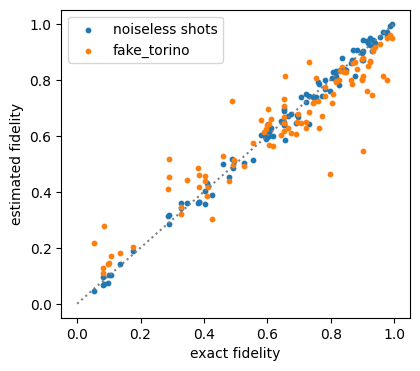

In [29]:
compiled = transpile([pair[0] for pair in measured], noisy_backend, optimization_level=1, seed_transpiler=SEED)
print("logical  : depth {:.0f}, two-qubit gates {:.1f}".format(
    np.mean([pair[0].depth() for pair in measured]),
    np.mean([sum(1 for i in pair[0].data if i.operation.num_qubits == 2) for pair in measured])))
print("on device: depth {:.0f}, two-qubit gates {:.1f}".format(
    np.mean([qc.depth() for qc in compiled]),
    np.mean([sum(1 for i in qc.data if i.operation.num_qubits == 2 and i.operation.name != "barrier") for qc in compiled])))

fig, ax = plt.subplots(figsize=(4.5, 4))
ax.scatter(exact.ravel(), noiseless["fidelity"].ravel(), s=10, label="noiseless shots")
ax.scatter(exact.ravel(), noisy["fidelity"].ravel(), s=10, label=noisy_backend.name)
ax.plot([0, 1], [0, 1], color="grey", ls=":")
ax.set(xlabel="exact fidelity", ylabel="estimated fidelity")
ax.legend()
plt.show()

**Q15 (6 marks).** (a) The estimate $\hat F = h/N$ from $N$ accepted shots is binomial. Give its standard error, and
use it to decide for how many emulated rows the noiseless comparison "positive > negative" is resolved at two standard
errors. (b) Plot the noiseless accuracy against the number of shots (e.g. $2^{10}$ to $2^{18}$) and explain the curve in terms of
(a) and Q13.

In [30]:
# Q15: your code here

**Answer Q15.** *Write your answer here.*

**Q16 (6 marks).** (a) Suppose the noise acted as a global depolarising channel of strength $p$ on the output qubits:
$\rho \mapsto (1-p)\rho + p\, I/2^k$. Show that the measured fidelity becomes $(1-p)F + p/2^k$ and that a ranking
between two images would be unchanged if both circuits had the same $p$. (b) Use the scatter plot and the transpiled
circuit statistics to explain why the real noise does not behave like this. How does noise interact with
post-selection?

**Answer Q16.** *Write your answer here.*

## Part 5. Discussion (12 marks)

**Q17 (12 marks).** In about 400 words, compare the classical tensor network with the quantum circuit model, using
your results. Cover accuracy on both tasks, number of parameters, the cost of training (exact contraction), and the
cost of inference on a device (qubits, shots, and $1/p_{\text{accept}}$). Using Q2, say under which conditions, if
any, evaluating such a model on a quantum computer could be preferable to contracting it classically. Distinguish
what your experiments show from what they do not.

**Answer Q17.** *Write your answer here.*

## 6. Optional: real hardware (not marked)

The emulated circuits can be sent to a real device unchanged. The cell below uses IBM Quantum through Qiskit Runtime's
`SamplerV2`. Save your account first with `QiskitRuntimeService.save_account(token=...)`, then set `RUN_HARDWARE = True`.
Queues can be long; start with a few rows. IQM devices need `iqm-client[qiskit]`, which pins an older Qiskit, so use a
separate environment for them: their `IQMProvider(url, token=...).get_backend()` works with the same `transpile` and
`run` calls as the emulators above.

In [31]:
RUN_HARDWARE = False

if RUN_HARDWARE:
    from qiskit_ibm_runtime import QiskitRuntimeService, SamplerV2

    backend = QiskitRuntimeService().least_busy(operational=True, simulator=False)
    flat = [qc for pair in measured[:10] for qc in pair]
    job = SamplerV2(mode=backend).run(transpile(flat, backend, optimization_level=1), shots=SHOTS)
    counts = [result.data.meas.get_counts() for result in job.result()]
    hardware = np.array([estimate_overlap(c, qc) for c, qc in zip(counts, flat)]).reshape(-1, 2, 2)
    print(backend.name, "accuracy:", np.mean(hardware[:, 0, 0] > hardware[:, 1, 0]))